# Event CNN vs SNN — temporal order & internal reps

Load trained `event_frame_cnn` and `event_frame_snn` checkpoints on the same
3-frame event polarity windows. Probe whether either model uses **temporal
order** by evaluating on reordered sequences, then compare **internal
representations** (CNN encoder maps vs SNN stage `_b` spike / membrane activity).

- Input layout: `(B, 6, H, W)` = 3 steps × 2 polarity channels
- CNN: all 6 channels as a static stack (order can still matter via channel slots)
- SNN: CNN-matched encoder–decoder; unrolls one polarity frame per step through LIF

**Note:** SNN must be retrained after the CNN-matched architecture change.


In [1]:
from __future__ import annotations

import itertools
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from horus.config import load_config, repo_root
from horus.data.dataset import build_dataloader
from horus.eval import ARCH_REGISTRY, load_model
from horus.eval.metrics import visible_pixel_distances
from horus.models import BallHeatmapCNN, BallHeatmapSNN, heatmap_to_coords
from horus.models.snn import LAYER_NAMES, STAGE_NAMES

CNN_ARCH = "event_frame_cnn"
SNN_ARCH = "event_frame_snn"
SPLIT = "val"
BATCH_SIZE = 64
SAMPLE_IDX = 0
STEPS = 3
POLARITY_CH = 2

# Named orders to highlight + all permutations for the summary table
FOCUS_ORDERS = OrderedDict(
    [
        ("original", (0, 1, 2)),
        ("reverse", (2, 1, 0)),
        ("swap_last", (0, 2, 1)),
        ("swap_first", (1, 0, 2)),
        ("rotate_l", (1, 2, 0)),
        ("rotate_r", (2, 0, 1)),
    ]
)

ROOT = repo_root()
cfg = load_config()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_, modality = ARCH_REGISTRY[CNN_ARCH]
assert ARCH_REGISTRY[SNN_ARCH][1] == modality

cnn_path = ROOT / "checkpoints" / f"{CNN_ARCH}.pt"
snn_path = ROOT / "checkpoints" / f"{SNN_ARCH}.pt"
for p in (cnn_path, snn_path):
    if not p.is_file():
        raise FileNotFoundError(f"Missing checkpoint: {p}")

cnn = load_model(CNN_ARCH, cnn_path, device)
snn = load_model(SNN_ARCH, snn_path, device)
assert isinstance(cnn, BallHeatmapCNN)
assert isinstance(snn, BallHeatmapSNN)

for arch, path in ((CNN_ARCH, cnn_path), (SNN_ARCH, snn_path)):
    meta = torch.load(path, map_location="cpu", weights_only=True)
    print(
        f"{arch}: epoch={meta.get('epoch')} val_px={meta.get('val_px'):.2f} "
        f"device={device}"
    )

loader = build_dataloader(
    cfg, SPLIT, modality, batch_size=BATCH_SIZE, num_workers=0, shuffle=False
)
batch = next(iter(loader))
x0 = batch["input"]  # (B, 6, H, W) on CPU
gt = batch["heatmap"]
coords = batch["coords"]
visible = batch["visible"]
print(f"batch input {tuple(x0.shape)}  visible={int((visible > 0.5).sum())}/{x0.shape[0]}")


event_frame_cnn: epoch=12 val_px=19.26 device=cuda
event_frame_snn: epoch=20 val_px=166.94 device=cuda
batch input (64, 6, 360, 640)  visible=64/64


## Helpers

Reorder polarity triples, preview events, pull CNN encoder maps via hooks, and
score predictions against GT coordinates.

In [2]:
def reorder_frames(x: torch.Tensor, order: tuple[int, ...]) -> torch.Tensor:
    """Permute the 3 polarity pairs in ``(B, 6, H, W)`` (or ``(6, H, W)``)."""
    squeeze = x.ndim == 3
    if squeeze:
        x = x.unsqueeze(0)
    b, c, h, w = x.shape
    expected = STEPS * POLARITY_CH
    if c != expected:
        raise ValueError(f"expected {expected} channels, got {c}")
    if len(order) != STEPS or sorted(order) != list(range(STEPS)):
        raise ValueError(f"order must be a permutation of 0..{STEPS - 1}, got {order}")
    y = x.view(b, STEPS, POLARITY_CH, h, w)[:, list(order)]
    y = y.reshape(b, c, h, w)
    return y.squeeze(0) if squeeze else y


def preview_event(chw: torch.Tensor, which: int = -1) -> np.ndarray:
    """Polarity pair as R=pos, B=neg. ``which`` indexes the time step."""
    x = chw.detach().float().cpu().numpy()
    _, h, w = x.shape
    frames = x.reshape(STEPS, POLARITY_CH, h, w)
    pos, neg = frames[which]
    scale = max(float(pos.max()), float(neg.max()), 1e-8)
    rgb = np.zeros((h, w, 3), dtype=np.float32)
    rgb[..., 0] = pos / scale
    rgb[..., 2] = neg / scale
    return np.clip(rgb, 0, 1)


def preview_sequence(chw: torch.Tensor) -> list[np.ndarray]:
    return [preview_event(chw, t) for t in range(STEPS)]


@torch.inference_mode()
def predict(model: torch.nn.Module, x: torch.Tensor) -> torch.Tensor:
    return model(x.to(device)).cpu()


def score_preds(pred: torch.Tensor) -> dict[str, float]:
    """Mean pixel error + Acc@5 / Acc@10 on visible samples in this batch."""
    dists = visible_pixel_distances(pred, coords, visible)
    if dists.numel() == 0:
        return {"mean_px": float("nan"), "acc@5": 0.0, "acc@10": 0.0, "n": 0}
    return {
        "mean_px": float(dists.mean().item()),
        "acc@5": float((dists <= 5).float().mean().item()),
        "acc@10": float((dists <= 10).float().mean().item()),
        "n": int(dists.numel()),
    }


CNN_LAYER_NAMES = ("down1", "down2", "down3", "bottleneck")


@torch.inference_mode()
def cnn_features(model: BallHeatmapCNN, x: torch.Tensor) -> dict[str, torch.Tensor]:
    """Encoder activations for one forward (CPU tensors)."""
    captured: dict[str, torch.Tensor] = {}
    hooks = []

    def _make(name: str):
        def _hook(_mod, _inp, out):
            captured[name] = out.detach().cpu()

        return _hook

    for name in CNN_LAYER_NAMES:
        hooks.append(getattr(model, name).register_forward_hook(_make(name)))
    try:
        _ = model(x.to(device))
    finally:
        for h in hooks:
            h.remove()
    return captured


@torch.inference_mode()
def snn_features(model: BallHeatmapSNN, x: torch.Tensor):
    """Heatmap + activity trace (spikes / membrane per LIF)."""
    heat, trace = model.forward_with_activity(x.to(device))
    return heat.cpu(), trace


def spatial_mean_map(feat: torch.Tensor) -> np.ndarray:
    """Mean over non-spatial dims → ``(H, W)``.

    Accepts ``(C,H,W)``, ``(T,C,H,W)``, or batched ``(B,...)`` (uses sample 0).
    """
    t = feat.detach().float()
    if t.ndim == 5:
        t = t[0]  # (T, C, H, W)
    if t.ndim == 4:
        # (B, C, H, W) or (T, C, H, W) — mean over leading dims except H,W
        t = t.mean(dim=tuple(range(t.ndim - 2)))
    elif t.ndim == 3:
        t = t.mean(dim=0)
    return t.cpu().numpy()


def cosine_maps(a: torch.Tensor, b: torch.Tensor) -> float:
    """Cosine similarity of two feature tensors after mean-pool to vectors."""
    va = a.detach().float().reshape(-1)
    vb = b.detach().float().reshape(-1)
    return float(F.cosine_similarity(va.unsqueeze(0), vb.unsqueeze(0)).item())


print("helpers ready; focus orders:", list(FOCUS_ORDERS.keys()))

helpers ready; focus orders: ['original', 'reverse', 'swap_last', 'swap_first', 'rotate_l', 'rotate_r']


## 1. Reordered input preview

Show the three polarity frames under the original order and under reverse —
same content, different temporal slots.

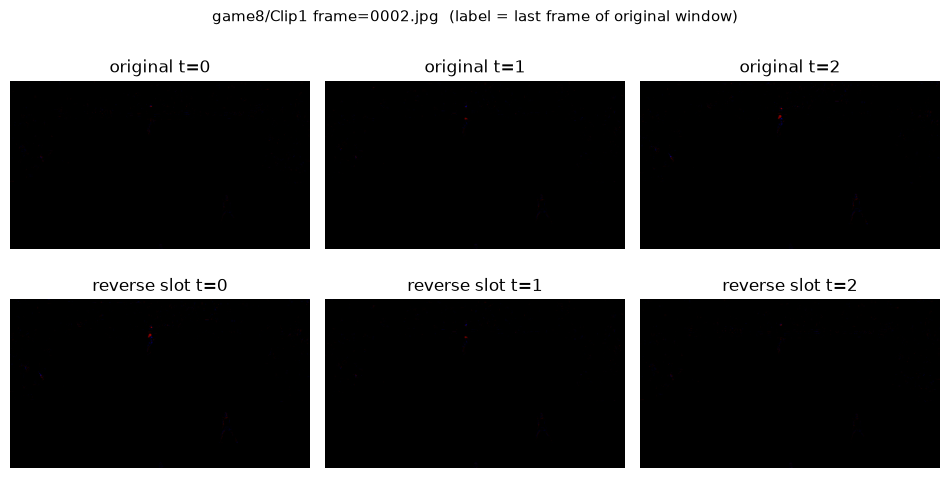

In [3]:
i = SAMPLE_IDX
x_sample = x0[i]
x_rev = reorder_frames(x_sample, FOCUS_ORDERS["reverse"])

fig, axes = plt.subplots(2, STEPS, figsize=(3.2 * STEPS, 5.2))
for t, frame in enumerate(preview_sequence(x_sample)):
    axes[0, t].imshow(frame)
    axes[0, t].set_title(f"original t={t}")
    axes[0, t].axis("off")
for t, frame in enumerate(preview_sequence(x_rev)):
    axes[1, t].imshow(frame)
    axes[1, t].set_title(f"reverse slot t={t}")
    axes[1, t].axis("off")
fig.suptitle(
    f"{batch['game'][i]}/{batch['clip'][i]} frame={batch['frame'][i]}  "
    f"(label = last frame of original window)",
    fontsize=11,
)
plt.tight_layout()
plt.show()

## 2. Temporal-order sensitivity (this batch)

Score CNN and SNN under every permutation of the three frames. If a model
relies on temporal dynamics / channel-slot order, **mean_px should rise** and
**Acc@k should fall** away from `original`. A flat table means the model mostly
ignores order (e.g. treating the stack as a bag of event images).

order        perm         cnn_px    Δcnn   cnn@5   snn_px    Δsnn   snn@5
------------------------------------------------------------------------
original     (0, 1, 2)     32.09   +0.00   46.9%   205.71   +0.00    1.6%
swap_last    (0, 2, 1)     94.17  +62.08   23.4%   196.70   -9.01    1.6%
swap_first   (1, 0, 2)     75.50  +43.41   42.2%   191.77  -13.93    1.6%
rotate_l     (1, 2, 0)     78.06  +45.97   40.6%   191.62  -14.09    1.6%
rotate_r     (2, 0, 1)    101.85  +69.75   23.4%   188.98  -16.72    1.6%
reverse      (2, 1, 0)    146.19 +114.09    4.7%   197.93   -7.78    3.1%


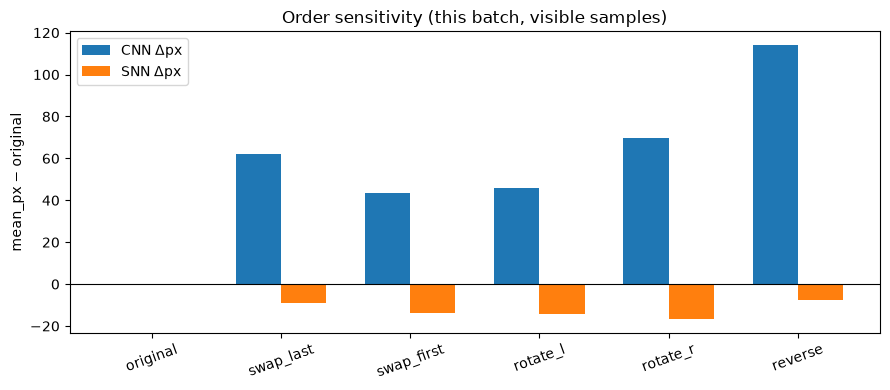

In [4]:
all_orders = list(itertools.permutations(range(STEPS)))
rows = []

for order in all_orders:
    name = next((k for k, v in FOCUS_ORDERS.items() if v == order), None)
    label = name if name else str(order)
    x_ord = reorder_frames(x0, order)
    cnn_pred = predict(cnn, x_ord)
    snn_pred = predict(snn, x_ord)
    cnn_s = score_preds(cnn_pred)
    snn_s = score_preds(snn_pred)
    rows.append(
        {
            "order": label,
            "perm": order,
            "cnn_px": cnn_s["mean_px"],
            "cnn_a5": cnn_s["acc@5"],
            "snn_px": snn_s["mean_px"],
            "snn_a5": snn_s["acc@5"],
            "cnn_pred": cnn_pred,
            "snn_pred": snn_pred,
        }
    )

# Reference = original order
base = next(r for r in rows if r["perm"] == (0, 1, 2))

print(
    f"{'order':<12} {'perm':<10} {'cnn_px':>8} {'Δcnn':>7} {'cnn@5':>7} "
    f"{'snn_px':>8} {'Δsnn':>7} {'snn@5':>7}"
)
print("-" * 72)
for r in rows:
    d_cnn = r["cnn_px"] - base["cnn_px"]
    d_snn = r["snn_px"] - base["snn_px"]
    print(
        f"{r['order']:<12} {str(r['perm']):<10} "
        f"{r['cnn_px']:8.2f} {d_cnn:+7.2f} {100 * r['cnn_a5']:6.1f}% "
        f"{r['snn_px']:8.2f} {d_snn:+7.2f} {100 * r['snn_a5']:6.1f}%"
    )

# Bar chart: Δ mean_px vs original for focus orders
focus_rows = [r for r in rows if r["order"] in FOCUS_ORDERS]
labels = [r["order"] for r in focus_rows]
x_pos = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    x_pos - width / 2,
    [r["cnn_px"] - base["cnn_px"] for r in focus_rows],
    width,
    label="CNN Δpx",
)
ax.bar(
    x_pos + width / 2,
    [r["snn_px"] - base["snn_px"] for r in focus_rows],
    width,
    label="SNN Δpx",
)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, rotation=20)
ax.set_ylabel("mean_px − original")
ax.set_title("Order sensitivity (this batch, visible samples)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Predictions under original vs reverse

Side-by-side heatmaps for both models on the same sample. Large shifts under
reverse imply the model was using temporal / slot structure.

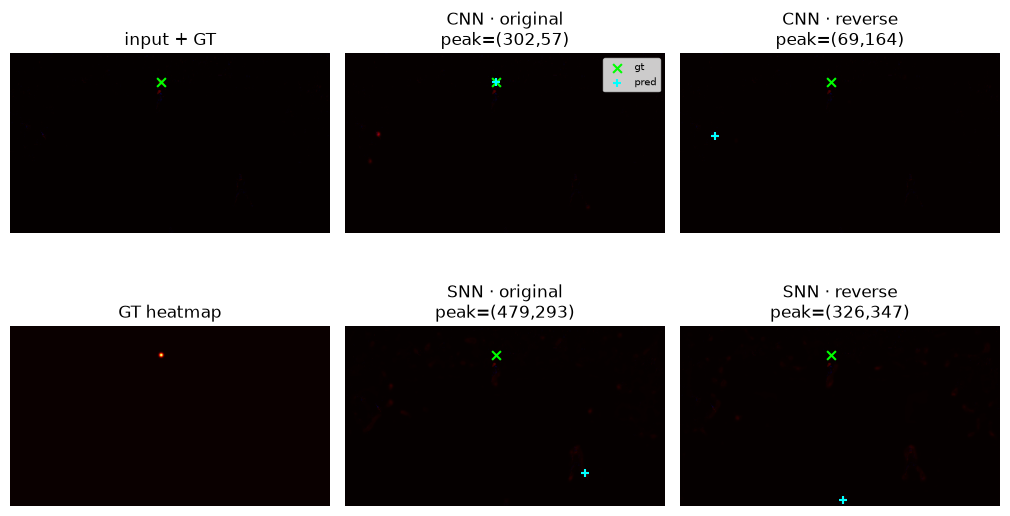

sample 0: peak shift from original prediction
  CNN reverse    Δpeak= 256.4 px
  SNN reverse    Δpeak= 162.2 px


In [5]:
compare_orders = ("original", "reverse")
i = SAMPLE_IDX
frame = preview_event(x0[i])
gx, gy = coords[i].tolist()

fig, axes = plt.subplots(2, len(compare_orders) + 1, figsize=(3.4 * (len(compare_orders) + 1), 6))
axes[0, 0].imshow(frame)
axes[0, 0].imshow(gt[i, 0].numpy(), cmap="hot", alpha=0.45, vmin=0, vmax=1)
axes[0, 0].scatter([gx], [gy], c="lime", s=40, marker="x")
axes[0, 0].set_title("input + GT")
axes[1, 0].imshow(gt[i, 0].numpy(), cmap="hot", vmin=0, vmax=1)
axes[1, 0].set_title("GT heatmap")

for col, name in enumerate(compare_orders, start=1):
    row = next(r for r in rows if r["order"] == name)
    for row_i, (key, title) in enumerate((("cnn_pred", "CNN"), ("snn_pred", "SNN"))):
        pred = row[key][i, 0].numpy()
        px, py = heatmap_to_coords(row[key])[i].tolist()
        axes[row_i, col].imshow(frame)
        axes[row_i, col].imshow(pred, cmap="hot", alpha=0.55, vmin=0, vmax=1)
        axes[row_i, col].scatter([gx], [gy], c="lime", s=40, marker="x", label="gt")
        axes[row_i, col].scatter([px], [py], c="cyan", s=40, marker="+", label="pred")
        axes[row_i, col].set_title(f"{title} · {name}\npeak=({px:.0f},{py:.0f})")
        if col == 1 and row_i == 0:
            axes[row_i, col].legend(loc="upper right", fontsize=7)

for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

# Peak displacement vs original prediction (how much the peak moves)
print(f"sample {i}: peak shift from original prediction")
for model_key, tag in (("cnn_pred", "CNN"), ("snn_pred", "SNN")):
    xy0 = heatmap_to_coords(base[model_key])[i]
    for name in compare_orders[1:]:
        row = next(r for r in rows if r["order"] == name)
        xy = heatmap_to_coords(row[model_key])[i]
        shift = float((xy - xy0).norm().item())
        print(f"  {tag:<3} {name:<10} Δpeak={shift:6.1f} px")

## 4. Internal representations — CNN encoder vs SNN LIFs

Qualitative comparison on the **original** window for one sample:

| CNN | SNN |
|-----|-----|
| `down1` / `down2` / `down3` / `bottleneck` mean activation | matching stage `_b` LIF spike rate & membrane |

Both models now share the same encoder–decoder spatial pyramid, so stage maps
align better. Look for *where* activity concentrates (ball trail, edges,
background).


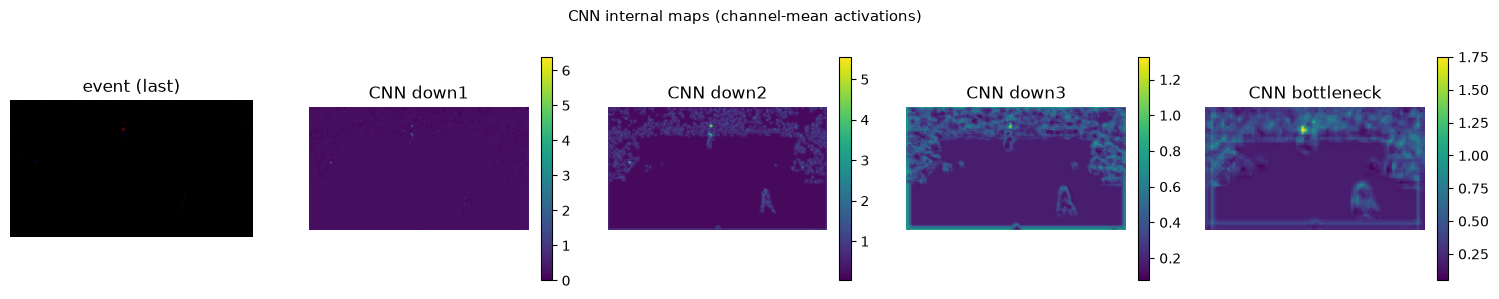

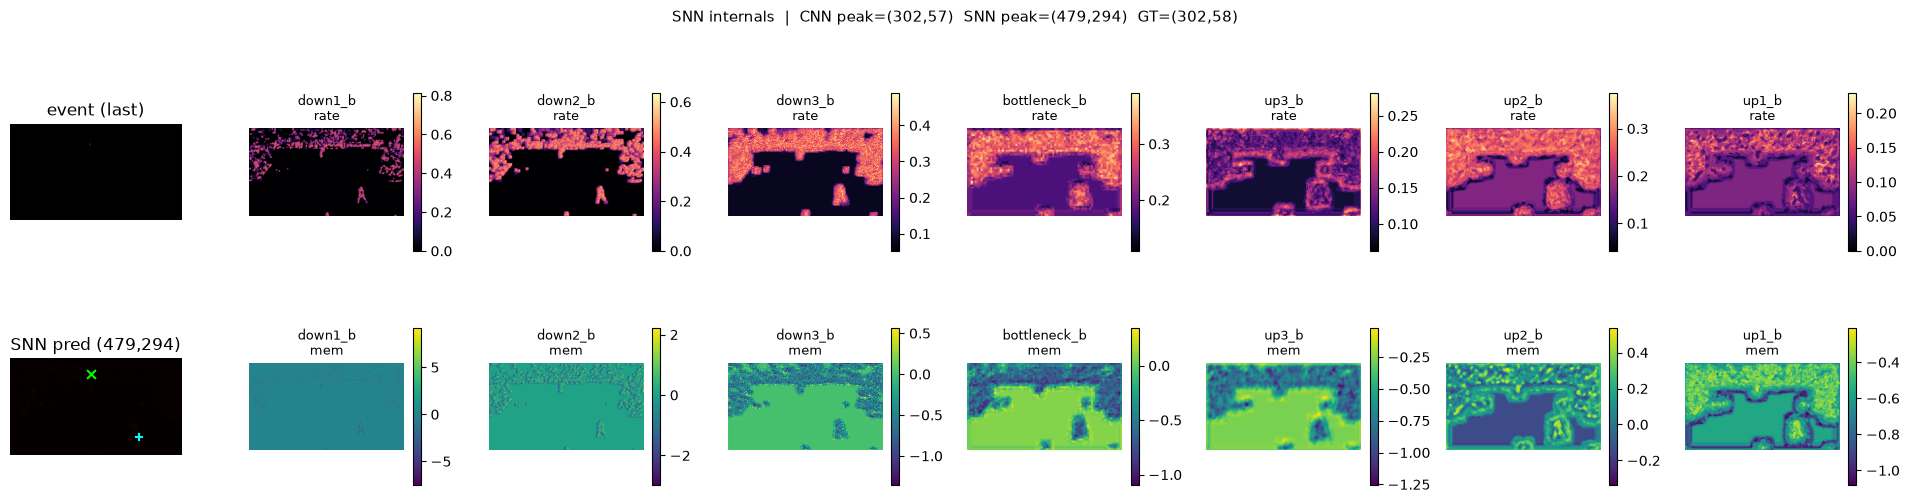

: 

In [ ]:
i = SAMPLE_IDX
x_one = x0[i : i + 1]
STAGE_LIF = tuple(f"{s}_b" for s in STAGE_NAMES)

cnn_feat = cnn_features(cnn, x_one)
snn_heat, snn_trace = snn_features(snn, x_one)
cnn_heat = predict(cnn, x_one)

frame = preview_event(x0[i])
gx, gy = coords[i].tolist()

# --- CNN encoder maps ---
fig, axes = plt.subplots(1, len(CNN_LAYER_NAMES) + 1, figsize=(3.0 * (len(CNN_LAYER_NAMES) + 1), 3.0))
axes[0].imshow(frame)
axes[0].set_title("event (last)")
for ax, name in zip(axes[1:], CNN_LAYER_NAMES):
    m = spatial_mean_map(cnn_feat[name][0])
    im = ax.imshow(m, cmap="viridis")
    ax.set_title(f"CNN {name}")
    fig.colorbar(im, ax=ax, fraction=0.046)
for ax in axes:
    ax.axis("off")
fig.suptitle("CNN internal maps (channel-mean activations)", fontsize=11)
plt.tight_layout()
plt.show()

# --- SNN spike rate + membrane (one column per spatial stage, _b LIF) ---
fig, axes = plt.subplots(2, len(STAGE_LIF) + 1, figsize=(2.4 * (len(STAGE_LIF) + 1), 5.5))
axes[0, 0].imshow(frame)
axes[0, 0].set_title("event (last)")
axes[1, 0].imshow(frame)
axes[1, 0].imshow(snn_heat[0, 0].numpy(), cmap="hot", alpha=0.55, vmin=0, vmax=1)
cpx, cpy = heatmap_to_coords(cnn_heat)[0].tolist()
spx, spy = heatmap_to_coords(snn_heat)[0].tolist()
axes[1, 0].scatter([gx], [gy], c="lime", s=40, marker="x")
axes[1, 0].scatter([spx], [spy], c="cyan", s=40, marker="+")
axes[1, 0].set_title(f"SNN pred ({spx:.0f},{spy:.0f})")

for col, name in enumerate(STAGE_LIF, start=1):
    layer = snn_trace[name]
    rate = spatial_mean_map(layer.spikes)
    mem = spatial_mean_map(layer.membrane)
    im = axes[0, col].imshow(rate, cmap="magma")
    axes[0, col].set_title(f"{name}\nrate", fontsize=9)
    fig.colorbar(im, ax=axes[0, col], fraction=0.046)
    im = axes[1, col].imshow(mem, cmap="viridis")
    axes[1, col].set_title(f"{name}\nmem", fontsize=9)
    fig.colorbar(im, ax=axes[1, col], fraction=0.046)

for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(
    f"SNN internals  |  CNN peak=({cpx:.0f},{cpy:.0f})  SNN peak=({spx:.0f},{spy:.0f})  GT=({gx:.0f},{gy:.0f})",
    fontsize=11,
)
plt.tight_layout()
plt.show()


## 5. Do internals change when order flips?

Cosine similarity of each layer's features under **original** vs **reverse**
(and other focus orders). Values near 1 ⇒ representation is order-invariant;
lower ⇒ the layer encodes temporal / slot structure.

Also plot paired CNN / SNN maps for original vs reverse on the same sample.

In [ ]:
i = SAMPLE_IDX
x_orig = x0[i : i + 1]
orders_to_probe = ["reverse", "swap_last", "rotate_l"]
# Cosine on stage _b LIFs (one per spatial stage) to keep the table readable.
PROBE_SNN = tuple(f"{s}_b" for s in STAGE_NAMES)

cnn_orig = cnn_features(cnn, x_orig)
_, snn_orig = snn_features(snn, x_orig)

print(f"{'order':<12} {'layer':<16} {'model':<5} {'cos(orig,*)':>12}")
print("-" * 50)
sim_records = []
for order_name in orders_to_probe:
    x_alt = reorder_frames(x0[i : i + 1], FOCUS_ORDERS[order_name])
    cnn_alt = cnn_features(cnn, x_alt)
    _, snn_alt = snn_features(snn, x_alt)

    for name in CNN_LAYER_NAMES:
        cos = cosine_maps(cnn_orig[name], cnn_alt[name])
        sim_records.append((order_name, name, "CNN", cos))
        print(f"{order_name:<12} {name:<16} {'CNN':<5} {cos:12.4f}")

    for name in PROBE_SNN:
        s0 = snn_orig[name].spikes.mean(dim=1)
        s1 = snn_alt[name].spikes.mean(dim=1)
        cos_s = cosine_maps(s0, s1)
        m0 = snn_orig[name].membrane.mean(dim=1)
        m1 = snn_alt[name].membrane.mean(dim=1)
        cos_m = cosine_maps(m0, m1)
        sim_records.append((order_name, f"{name}/spk", "SNN", cos_s))
        sim_records.append((order_name, f"{name}/mem", "SNN", cos_m))
        print(f"{order_name:<12} {name + '/spk':<16} {'SNN':<5} {cos_s:12.4f}")
        print(f"{order_name:<12} {name + '/mem':<16} {'SNN':<5} {cos_m:12.4f}")

# Grouped bar: cosine under reverse for CNN layers vs SNN spike layers
rev = [r for r in sim_records if r[0] == "reverse"]
cnn_rev = [(n, c) for _, n, m, c in rev if m == "CNN"]
snn_rev = [(n, c) for _, n, m, c in rev if m == "SNN" and n.endswith("/spk")]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
axes[0].bar(range(len(cnn_rev)), [c for _, c in cnn_rev], color="C0")
axes[0].set_xticks(range(len(cnn_rev)))
axes[0].set_xticklabels([n for n, _ in cnn_rev], rotation=25)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("CNN: cos(orig, reverse)")
axes[0].set_ylabel("cosine similarity")

axes[1].bar(range(len(snn_rev)), [c for _, c in snn_rev], color="C1")
axes[1].set_xticks(range(len(snn_rev)))
axes[1].set_xticklabels([n for n, _ in snn_rev], rotation=25)
axes[1].set_title("SNN stage_b spikes: cos(orig, reverse)")
for ax in axes:
    ax.axhline(1.0, color="k", lw=0.6, ls="--")
plt.tight_layout()
plt.show()


In [ ]:
# Visual: matched stages under original vs reverse
i = SAMPLE_IDX
x_orig = x0[i : i + 1]
x_rev = reorder_frames(x_orig, FOCUS_ORDERS["reverse"])

cnn_o = cnn_features(cnn, x_orig)
cnn_r = cnn_features(cnn, x_rev)
_, snn_o = snn_features(snn, x_orig)
_, snn_r = snn_features(snn, x_rev)

pairs = [
    ("CNN down1", spatial_mean_map(cnn_o["down1"]), spatial_mean_map(cnn_r["down1"]), "viridis"),
    ("CNN bottleneck", spatial_mean_map(cnn_o["bottleneck"]), spatial_mean_map(cnn_r["bottleneck"]), "viridis"),
    ("SNN down1_b rate", spatial_mean_map(snn_o["down1_b"].spikes), spatial_mean_map(snn_r["down1_b"].spikes), "magma"),
    ("SNN bottleneck_b rate", spatial_mean_map(snn_o["bottleneck_b"].spikes), spatial_mean_map(snn_r["bottleneck_b"].spikes), "magma"),
    ("SNN up1_b mem", spatial_mean_map(snn_o["up1_b"].membrane), spatial_mean_map(snn_r["up1_b"].membrane), "viridis"),
]

fig, axes = plt.subplots(len(pairs), 3, figsize=(9, 2.4 * len(pairs)))
for row, (title, a, b, cmap) in enumerate(pairs):
    vmin = min(a.min(), b.min())
    vmax = max(a.max(), b.max())
    axes[row, 0].imshow(a, cmap=cmap, vmin=vmin, vmax=vmax)
    axes[row, 0].set_title(f"{title} · original")
    axes[row, 1].imshow(b, cmap=cmap, vmin=vmin, vmax=vmax)
    axes[row, 1].set_title(f"{title} · reverse")
    diff = np.abs(a - b)
    im = axes[row, 2].imshow(diff, cmap="hot")
    axes[row, 2].set_title("|Δ|")
    fig.colorbar(im, ax=axes[row, 2], fraction=0.046)
    for ax in axes[row]:
        ax.axis("off")
fig.suptitle("Internal maps: original vs reverse (same sample)", fontsize=12)
plt.tight_layout()
plt.show()


## 6. Optional: multi-batch order sensitivity

Aggregate mean_px over more val batches for `original` vs `reverse` only.
Set `MAX_BATCHES` higher for a stabler estimate.

In [ ]:
MAX_BATCHES = 20
probe = OrderedDict([("original", (0, 1, 2)), ("reverse", (2, 1, 0))])

accum = {
    name: {"cnn": [], "snn": []} for name in probe
}

n_batches = 0
with torch.inference_mode():
    for batch_i, b in enumerate(loader):
        if batch_i >= MAX_BATCHES:
            break
        x = b["input"]
        coords_b = b["coords"]
        vis_b = b["visible"]
        for name, order in probe.items():
            x_ord = reorder_frames(x, order)
            for tag, model in (("cnn", cnn), ("snn", snn)):
                pred = model(x_ord.to(device)).cpu()
                dists = visible_pixel_distances(pred, coords_b, vis_b)
                if dists.numel():
                    accum[name][tag].append(dists)
        n_batches += 1


def _cat_mean(chunks: list[torch.Tensor]) -> float:
    if not chunks:
        return float("nan")
    return float(torch.cat(chunks).mean().item())


print(f"aggregated over {n_batches} batch(es)\n")
print(f"{'order':<12} {'cnn_px':>10} {'snn_px':>10}")
print("-" * 34)
summary = {}
for name in probe:
    c = _cat_mean(accum[name]["cnn"])
    s = _cat_mean(accum[name]["snn"])
    summary[name] = (c, s)
    print(f"{name:<12} {c:10.2f} {s:10.2f}")

if "original" in summary and "reverse" in summary:
    print(
        f"\nΔ reverse−original:  CNN={summary['reverse'][0] - summary['original'][0]:+.2f} px  "
        f"SNN={summary['reverse'][1] - summary['original'][1]:+.2f} px"
    )